# handling missing categorical data

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('train (1).csv',usecols = ['GarageQual','FireplaceQu','SalePrice'])

In [6]:
df.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [7]:
df.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

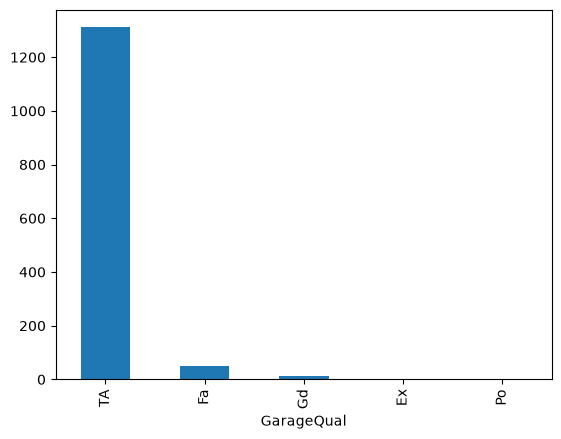

In [8]:
df['GarageQual'].value_counts().sort_values(ascending = False).plot.bar()
plt.xlabel = ('GarageQual')
plt.ylabel = ('Number of houses')

<Axes: xlabel='GarageQual'>

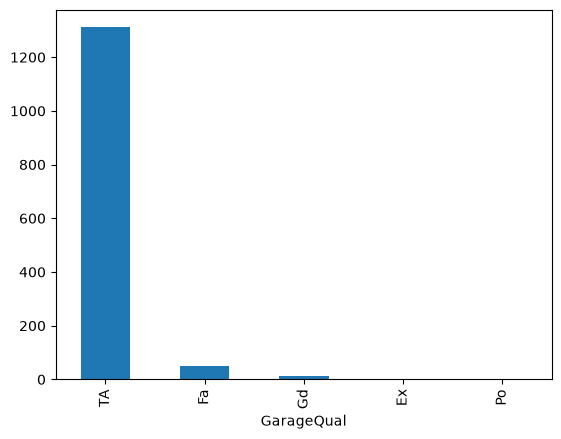

In [9]:
df['GarageQual'].value_counts().plot(kind='bar')

In [10]:
df['GarageQual'].mode()

0    TA
Name: GarageQual, dtype: str

Text(0.5, 1.0, 'GarageQual')

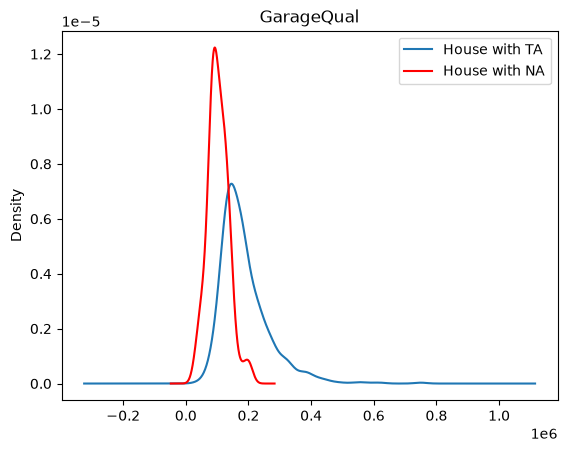

In [11]:
fig = plt.figure()
ax = fig.add_subplot(111)

df[df['GarageQual']=='TA']['SalePrice'].plot(kind = 'kde', ax= ax)

df[df['GarageQual'].isnull()]['SalePrice'].plot(kind= 'kde', ax = ax , color = 'red')

lines,labels = ax.get_legend_handles_labels()
labels = ['House with TA', 'House with NA']
ax.legend(lines, labels, loc='best')

plt.title('GarageQual')

In [12]:
temp= df[df['GarageQual']=='TA']['SalePrice']


In [13]:
df['GarageQual'].fillna('TA',inplace=True)

C:\Users\vaibh\AppData\Local\Temp\ipykernel_20084\584385255.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['GarageQual'].fillna('TA',inplace=True)


0       TA
1       TA
2       TA
3       TA
4       TA
        ..
1455    TA
1456    TA
1457    TA
1458    TA
1459    TA
Name: GarageQual, Length: 1460, dtype: str

<Axes: xlabel='GarageQual'>

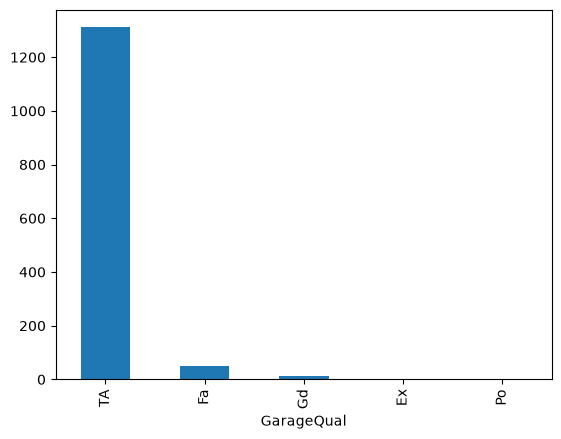

In [14]:
df['GarageQual'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'GarageQual')

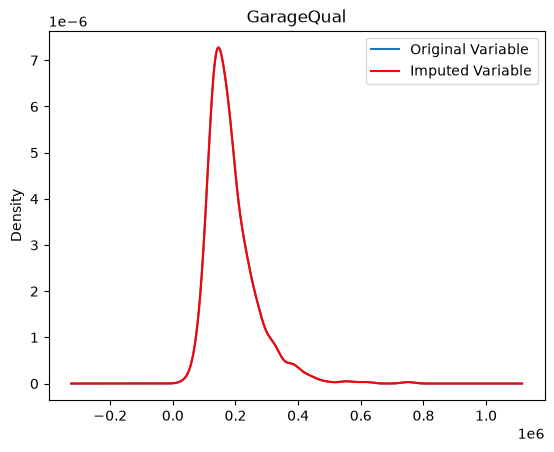

In [15]:
fig = plt.figure()
ax = fig.add_subplot(111)

temp.plot(kind='kde',ax=ax)

df[df['GarageQual']=='TA']['SalePrice'].plot(kind = 'kde', ax= ax,color = 'red')

# df[df['GarageQual'].isnull()]['SalePrice'].plot(kind= 'kde', ax = ax , color = 'red')

lines,labels = ax.get_legend_handles_labels()
labels = ['Original Variable', 'Imputed Variable']
ax.legend(lines, labels, loc='best')

plt.title('GarageQual')

<Axes: xlabel='FireplaceQu'>

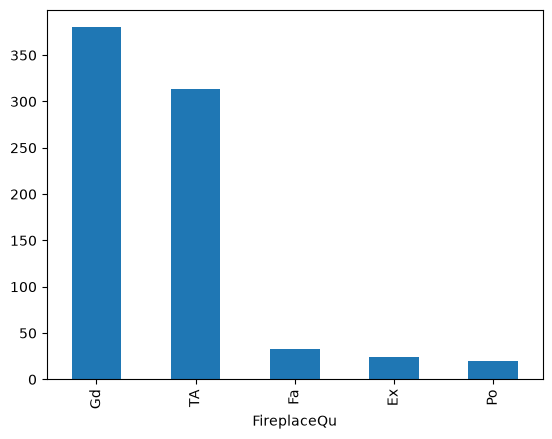

In [16]:
df['FireplaceQu'].value_counts().plot(kind = 'bar')

In [17]:
df['FireplaceQu'].mode()

0    Gd
Name: FireplaceQu, dtype: str

Text(0.5, 1.0, 'FireplaceQu')

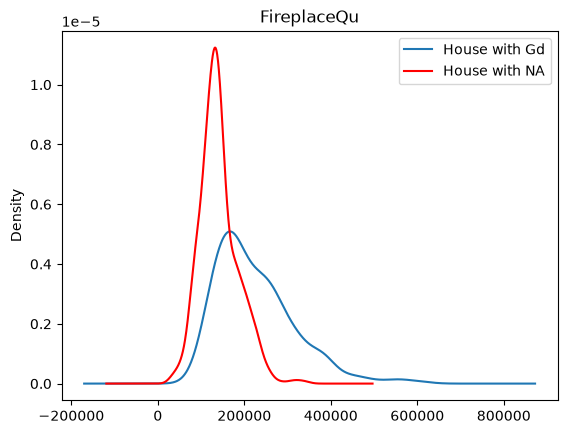

In [20]:
fig = plt.figure()
ax = fig.add_subplot(111)



df[df['FireplaceQu']=='Gd']['SalePrice'].plot(kind = 'kde', ax= ax)

df[df['FireplaceQu'].isnull()]['SalePrice'].plot(kind= 'kde', ax = ax , color = 'red')

lines,labels = ax.get_legend_handles_labels()
labels = ['House with Gd', 'House with NA']
ax.legend(lines, labels, loc='best')

plt.title('FireplaceQu')

In [21]:
temp = df[df['FireplaceQu']=='Gd']['SalePrice']

In [22]:
df['FireplaceQu'].fillna('Gd',inplace=True)

C:\Users\vaibh\AppData\Local\Temp\ipykernel_20084\891419280.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['FireplaceQu'].fillna('Gd',inplace=True)


0       Gd
1       TA
2       TA
3       Gd
4       TA
        ..
1455    TA
1456    TA
1457    Gd
1458    Gd
1459    Gd
Name: FireplaceQu, Length: 1460, dtype: str

<Axes: xlabel='FireplaceQu'>

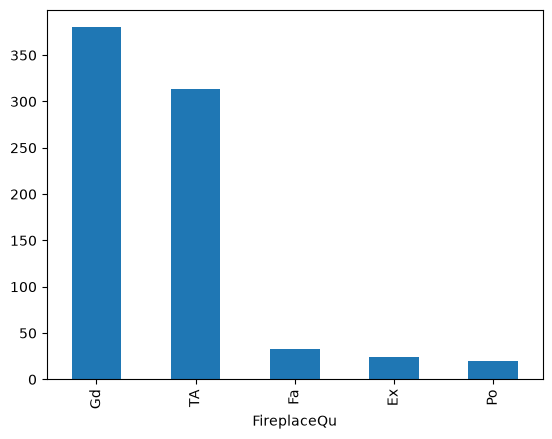

In [23]:
df['FireplaceQu'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'FireplaceQu')

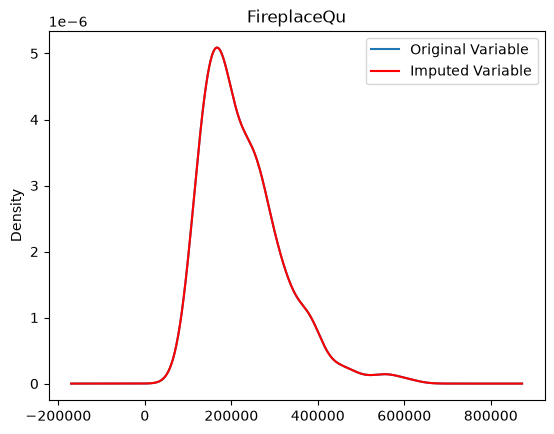

In [26]:
fig = plt.figure()
ax = fig.add_subplot(111)

temp.plot(kind='kde',ax=ax)

df[df['FireplaceQu']=='Gd']['SalePrice'].plot(kind = 'kde', ax= ax,color = 'red')

# df[df['GarageQual'].isnull()]['SalePrice'].plot(kind= 'kde', ax = ax , color = 'red')

lines,labels = ax.get_legend_handles_labels()
labels = ['Original Variable', 'Imputed Variable']
ax.legend(lines, labels, loc='best')

plt.title('FireplaceQu')

In [28]:
from sklearn.model_selection import train_test_split
X_train,X_test ,y_train , y_test =train_test_split(df.drop(columns=['SalePrice']),df['SalePrice'],test_size= 0.2)

In [29]:
from sklearn.impute import SimpleImputer


In [30]:
imputer = SimpleImputer(strategy='most_frequent')

In [31]:
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [32]:
imputer.statistics_

array(['Gd', 'TA'], dtype=object)